# 05 · Pretrained models (GPU)

Can models pretrained on large molecule or table collections make up for having only 114 substrates?

- **CheMeleon** (chemprop foundation model, weights from `precursor2cof-capacitance`, copied to `pretrained/`):
  - *frozen:* mean-pooled 2048-d embeddings fed to BRR, ridge, a GP (RBF on 20 PCA components) and RF
  - *fine-tuned:* the whole message-passing network + a regression head trained on log(y) in every fold
    (50 epochs, no validation split). This is what the old pipeline did, but on the raw target.
- **TabPFN v2** (a transformer pretrained on synthetic tabular tasks) without hyperparameter search,
  on several feature sets, raw and log target. The old pipeline tuned it with 100 trials per fold.

Needs the `gpu` dependency group (installed by default).

In [1]:
import logging
import os
import sys
import warnings

os.environ["PYTHONWARNINGS"] = "ignore"
warnings.filterwarnings("ignore")
for name in ["lightning", "lightning.pytorch", "lightning.fabric"]:
    logging.getLogger(name).setLevel(logging.ERROR)
sys.path.insert(0, os.path.abspath(".."))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestRegressor
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, ConstantKernel, WhiteKernel
from sklearn.linear_model import BayesianRidge, RidgeCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from tabpfn import TabPFNRegressor

from cofreg import plots
from cofreg.cv import cross_val_oof, load_oof, pooled_scores, repeated_folds, run_many, summarize
from cofreg.data import RESULTS_DIR, load_data, load_features
from cofreg.features import rdkit_descriptors, redox_features
from cofreg.models import TargetTransformed
from cofreg.pretrained import ChemeleonFinetune, cached_chemeleon

plots.style()
torch.set_float32_matmul_precision("high")
EXPERIMENT = "05_pretrained"
data = load_data()
y = data.capacity_max.to_numpy()
smiles = data.smiles.tolist()
repeats = repeated_folds(y)
log = lambda model: TargetTransformed(model, "log")
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none")

GPU: NVIDIA GeForce RTX 3090


## Frozen CheMeleon embeddings

In [2]:
emb = cached_chemeleon(smiles)
gp_pca = lambda: make_pipeline(
    StandardScaler(), PCA(20, random_state=0), GaussianProcessRegressor(ConstantKernel() * RBF(5.0) + WhiteKernel(0.1), normalize_y=True, n_restarts_optimizer=2, random_state=0)
)
frozen = [
    ("chemeleon_frozen + brr", log(make_pipeline(StandardScaler(), BayesianRidge())), emb, "chemeleon"),
    ("chemeleon_frozen + ridge", log(make_pipeline(StandardScaler(), RidgeCV(np.logspace(-1, 5, 25)))), emb, "chemeleon"),
    ("chemeleon_frozen + gp(pca20)", log(gp_pca()), emb, "chemeleon"),
    ("chemeleon_frozen + rf", log(RandomForestRegressor(500, min_samples_leaf=2, max_features=0.3, random_state=0, n_jobs=1)), emb, "chemeleon"),
]
summary_frozen = run_many(frozen, y, repeats, EXPERIMENT)

chemeleon_frozen + brr                        MAPE 2.623±0.033  PA 0.623±0.010  RMSE 213.0±1.8  MALE 0.910  (2.6s)
chemeleon_frozen + ridge                      MAPE 2.521±0.063  PA 0.616±0.011  RMSE 217.2±3.8  MALE 0.938  (0.2s)


chemeleon_frozen + gp(pca20)                  MAPE 1.565±0.016  PA 0.616±0.010  RMSE 208.9±0.8  MALE 0.789  (0.7s)


chemeleon_frozen + rf                         MAPE 1.988±0.061  PA 0.650±0.011  RMSE 203.6±2.4  MALE 0.811  (30.6s)


## TabPFN without tuning

Default TabPFN regressor (8 ensemble members). Features with more than 500 columns are reduced: the
CheMeleon embedding goes through PCA (50 components).

In [3]:
X_rf = load_features("estate", "functional_groups")
desc = load_features("descriptor")
rd_redox = pd.concat([rdkit_descriptors(smiles), redox_features(smiles)], axis=1)
tab = lambda: TabPFNRegressor(device="cuda", random_state=0, n_estimators=8)
tabpfn = [
    ("tabpfn_raw | descriptor", tab(), desc, "descriptor"),
    ("tabpfn | descriptor", log(tab()), desc, "descriptor"),
    ("tabpfn_raw | estate+fg", tab(), X_rf, "estate+fg"),
    ("tabpfn | estate+fg", log(tab()), X_rf, "estate+fg"),
    ("tabpfn_raw | rdkit+redox", tab(), rd_redox, "rdkit+redox"),
    ("tabpfn | rdkit+redox", log(tab()), rd_redox, "rdkit+redox"),
    ("tabpfn | chemeleon pca50", log(make_pipeline(StandardScaler(), PCA(50, random_state=0), tab())), emb, "chemeleon"),
]
summary_tabpfn = run_many(tabpfn, y, repeats, EXPERIMENT, n_jobs=1)

tabpfn_raw | descriptor                       MAPE 3.853±0.059  PA 0.627±0.012  RMSE 187.4±2.0  MALE 0.831  (74.1s)


tabpfn | descriptor                           MAPE 2.285±0.039  PA 0.635±0.011  RMSE 202.9±2.8  MALE 0.808  (80.9s)


tabpfn_raw | estate+fg                        MAPE 3.117±0.154  PA 0.661±0.009  RMSE 178.8±1.4  MALE 0.783  (120.9s)


tabpfn | estate+fg                            MAPE 1.667±0.052  PA 0.674±0.008  RMSE 187.1±1.4  MALE 0.692  (121.0s)


tabpfn_raw | rdkit+redox                      MAPE 2.521±0.069  PA 0.667±0.007  RMSE 176.9±1.6  MALE 0.724  (167.8s)


tabpfn | rdkit+redox                          MAPE 1.652±0.053  PA 0.677±0.007  RMSE 183.1±2.5  MALE 0.678  (167.1s)


tabpfn | chemeleon pca50                      MAPE 2.203±0.097  PA 0.638±0.010  RMSE 196.7±3.7  MALE 0.804  (222.6s)


## Fine-tuned CheMeleon

50 folds × 50 epochs on the GPU, about 20–40 minutes. Saved predictions are reused if present
(delete `results/05_pretrained/chemeleon_finetune.csv` to retrain).

In [4]:
name = "chemeleon_finetune"
path = os.path.join(RESULTS_DIR, EXPERIMENT, f"{name}.csv")
X_idx = np.arange(len(y), dtype=float).reshape(-1, 1)
if os.path.exists(path):
    _, oof_ft = load_oof(EXPERIMENT, name)
    row = {"experiment": EXPERIMENT, "model": name, "features": "smiles (graph)", "n_features": 0} | summarize(pooled_scores(y, oof_ft))
    summary_ft = pd.DataFrame([row])
else:
    summary_ft = run_many([(name, log(ChemeleonFinetune(tuple(smiles), epochs=50)), X_idx, "smiles (graph)")], y, repeats, EXPERIMENT, n_jobs=1)
summary_ft

,experiment,model,features,n_features,mape_mean,mape_std,pa_mean,pa_std,rmse_mean,rmse_std,smape_mean,smape_std,mae_mean,mae_std,r2_mean,r2_std,male_mean,male_std,mape_ge20_mean,mape_ge20_std
0,05_pretrained,chemeleon_finetune,smiles (graph),0,3.630564,0.310599,0.614255,0.009666,225.818281,8.226447,0.732604,0.025104,166.783784,7.679128,-0.332965,0.097888,0.936718,0.044181,0.904417,0.058363


In [5]:
summary = pd.concat([summary_frozen, summary_tabpfn, summary_ft], ignore_index=True)
summary.to_csv(os.path.join(RESULTS_DIR, EXPERIMENT, "summary.csv"), index=False)
summary[["model", "mape_mean", "pa_mean", "pa_std", "rmse_mean", "male_mean", "mape_ge20_mean", "r2_mean"]].round(3)

,model,mape_mean,pa_mean,pa_std,rmse_mean,male_mean,mape_ge20_mean,r2_mean
0,chemeleon_frozen + brr,2.623,0.623,0.010,213.000,0.910,0.746,-0.185
1,chemeleon_frozen + ridge,2.521,0.616,0.011,217.194,0.938,0.787,-0.232
2,chemeleon_frozen + gp(pca20),1.565,0.616,0.010,208.949,0.789,0.715,-0.140
3,chemeleon_frozen + rf,1.988,0.650,0.011,203.649,0.811,0.684,-0.083
4,tabpfn_raw | descriptor,3.853,0.627,0.012,187.449,0.831,0.995,0.082
5,tabpfn | descriptor,2.285,0.635,0.011,202.935,0.808,0.694,-0.076
6,tabpfn_raw | estate+fg,3.117,0.661,0.009,178.805,0.783,0.959,0.165
7,tabpfn | estate+fg,1.667,0.674,0.008,187.134,0.692,0.671,0.086
8,tabpfn_raw | rdkit+redox,2.521,0.667,0.007,176.920,0.724,0.952,0.183
9,tabpfn | rdkit+redox,1.652,0.677,0.007,183.113,0.678,0.670,0.124


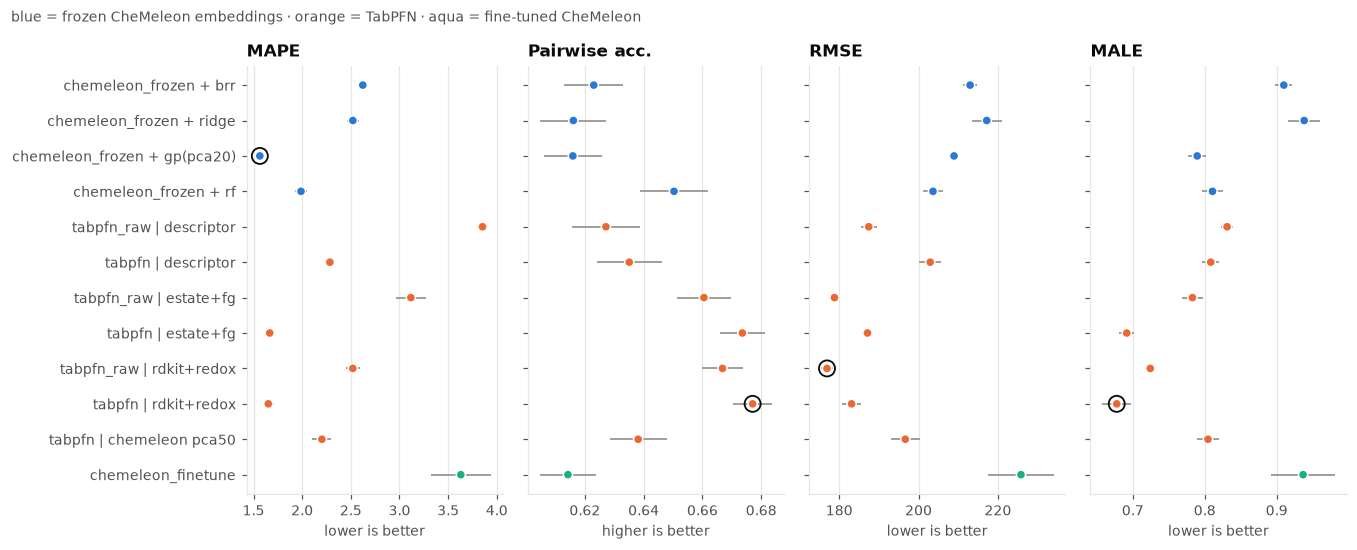

In [6]:
hl = {m: plots.ORANGE if m.startswith("tabpfn") else plots.AQUA if "finetune" in m else plots.BLUE for m in summary["model"]}
fig = plots.metric_dots(summary, highlight=hl)
fig.suptitle("blue = frozen CheMeleon embeddings · orange = TabPFN · aqua = fine-tuned CheMeleon", x=0.01, ha="left", fontsize=9, color=plots.INK_2)
fig.tight_layout()

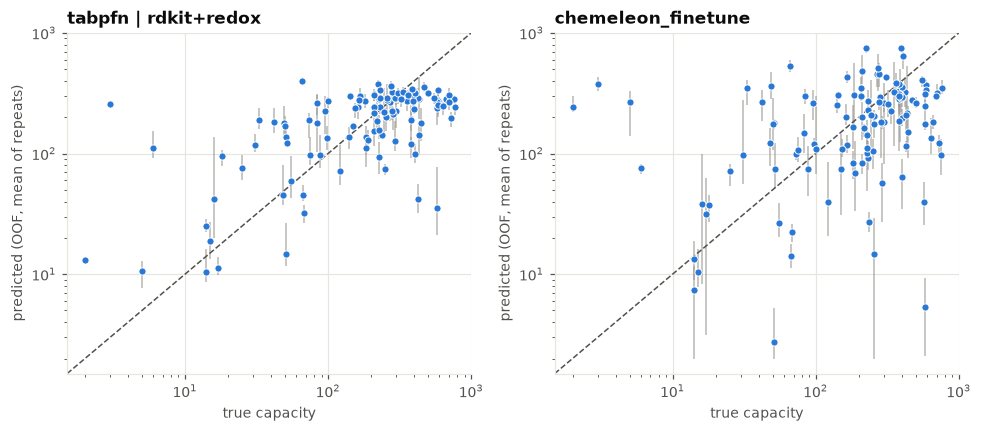

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
for ax, n in zip(axes, ["tabpfn | rdkit+redox", "chemeleon_finetune"]):
    plots.pred_vs_true(y, load_oof(EXPERIMENT, n)[1], n, ax=ax)
fig.tight_layout()

## Is fine-tuning just over-trained?

The 50-epoch model is good in some folds (MALE ≈ 0.6) and very bad in others (≈ 1.2), which looks like
overfitting without early stopping. Quick check on the first CV repeat only: shorter training and a
lower learning rate (about 3 minutes).

In [8]:
rows = []
for epochs, lr in [(10, None), (20, None), (20, 3e-4)]:
    oof = cross_val_oof(log(ChemeleonFinetune(tuple(smiles), epochs=epochs, lr=lr)), X_idx, y, repeats[:1], n_jobs=1)
    rows.append({"epochs": epochs, "max_lr": lr or "default (1e-3)"} | pooled_scores(y, oof).iloc[0][["mape", "pa", "rmse", "male"]].to_dict())
pd.DataFrame(rows).round(3)

,epochs,max_lr,mape,pa,rmse,male
0,10,default (1e-3),2.374,0.642,199.802,0.846
1,20,default (1e-3),2.694,0.622,212.419,0.904
2,20,0.0003,2.286,0.642,210.758,0.873


## Takeaways

- **Pretraining doesn't help on this data.** Frozen CheMeleon embeddings are worse than plain
  fingerprints with the same models (best: RF, PA 0.650 vs 0.677). Fine-tuning CheMeleon is the worst
  model in this study (PA 0.614, MALE 0.94, worse than the median baseline on MALE). Shorter training
  improves it (10 epochs: PA ≈ 0.64) but not to the level of the tree models.
- **TabPFN without tuning is competitive** with random forest: on RDKit descriptors + redox features
  with a log target it reaches PA 0.677 and MALE 0.678 (the lowest MALE so far), and with the raw
  target it has the lowest RMSE of all runs (176.9). It is not clearly better than RF, though, and
  needs a GPU.
- As everywhere, the log target trades a bit of RMSE for much lower MAPE.